# EDA

Dedicaremos este primer notebook a realizar un análisis exploratorio de los datos.

Comenzamos importando las librerías necesarias y conectándonos a Redshift para importar los datos de la capa 'curated'.

In [66]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import redshift_connector
import boto3

pd.set_option('display.max_columns', 180)
pd.set_option('display.max_rows', 180)

In [ ]:
host = "redshift-tfm-curated.159012148774.eu-west-3.redshift-serverless.amazonaws.com"
database = "redshift-tfm-curated"
user = "tfm_admin"

# Se ha eliminado por privacidad la contraseña
password = ""
port = 5439

conn = redshift_connector.connect(
    host=host,
    database=database,
    user=user,
    password=password,
    port=port
)

# Comprobamos la conexión a Redshift
print("Conexión correcta")

Conexión correcta


Una vez que se ha comprobado que la conexión a Redshift se ha establecido correctamente, importamos los datos mediante una consulta SQL a la base de datos.

In [40]:
QUERY = f"""
SELECT *
FROM curated.municipios
ORDER BY codigo_ine
"""

with conn.cursor() as cursor:
    cursor.execute(QUERY)
    df = cursor.fetch_dataframe()

print(f'Filas: {len(df):,} | Columnas: {df.shape[1]:,}')
display(df.head())

Filas: 8,132 | Columnas: 105


,codigo_ine,municipio,provincia,capital,poblacion_ign,superficie_km2,densidad_poblacion_hab_km2,longitud,latitud,codigo_comunidad,...,transacciones_segunda_mano_por_1000_inmuebles_residenciales,diferencia_transacciones_1_anio_por_1000_inmuebles_residenciales,diferencia_transacciones_3_anios_por_1000_inmuebles_residenciales,diferencia_transacciones_5_anios_por_1000_inmuebles_residenciales,diferencia_transacciones_nuevas_1_anio_por_1000_inmuebles_residenciales,diferencia_transacciones_nuevas_3_anios_por_1000_inmuebles_residenciales,diferencia_transacciones_nuevas_5_anios_por_1000_inmuebles_residenciales,diferencia_transacciones_segunda_mano_1_anio_por_1000_inmuebles_residenciales,diferencia_transacciones_segunda_mano_3_anios_por_1000_inmuebles_residenciales,diferencia_transacciones_segunda_mano_5_anios_por_1000_inmuebles_residenciales
0,01001,Alegría-Dulantzi,Araba/Álava,Alegría-Dulantzi,2965,19.95,148.62,-2.512508,42.840452,None,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,01002,Amurrio,Araba/Álava,Amurrio,10312,96.19,107.20,-3.001015,43.052658,None,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,01003,Aramaio,Araba/Álava,Ibarra,1380,73.09,18.88,-2.564829,43.052579,None,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,01004,Artziniega,Araba/Álava,Artziniega,1856,27.29,68.01,-3.130521,43.121792,None,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,01006,Armiñón,Araba/Álava,Armiñón,246,12.97,18.97,-2.872271,42.723409,None,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [44]:
# Se muestran los principales estadísticos descriptivos del dataset
df.describe()

,poblacion_ign,superficie_km2,densidad_poblacion_hab_km2,longitud,latitud,inmuebles_urbanos,valor_catastral_total_eur,valor_catastral_suelo_eur,superficie_urbana_m2,parcelas_urbanas,...,transacciones_segunda_mano_por_1000_inmuebles_residenciales,diferencia_transacciones_1_anio_por_1000_inmuebles_residenciales,diferencia_transacciones_3_anios_por_1000_inmuebles_residenciales,diferencia_transacciones_5_anios_por_1000_inmuebles_residenciales,diferencia_transacciones_nuevas_1_anio_por_1000_inmuebles_residenciales,diferencia_transacciones_nuevas_3_anios_por_1000_inmuebles_residenciales,diferencia_transacciones_nuevas_5_anios_por_1000_inmuebles_residenciales,diferencia_transacciones_segunda_mano_1_anio_por_1000_inmuebles_residenciales,diferencia_transacciones_segunda_mano_3_anios_por_1000_inmuebles_residenciales,diferencia_transacciones_segunda_mano_5_anios_por_1000_inmuebles_residenciales
count,8.132000e+03,8132.000000,8132.000000,8132.000000,8132.000000,7.606000e+03,7.606000e+03,7.606000e+03,7.606000e+03,7606.000000,...,7606.000000,7606.000000,7603.000000,7604.000000,7606.000000,7603.000000,7604.000000,7606.000000,7603.000000,7604.000000
mean,5.978811e+03,62.071045,184.693416,-3.107776,40.725184,5.285732e+03,3.196876e+08,1.579741e+08,1.381313e+06,1855.685643,...,19.557290,2.183903,3.055370,8.183549,0.042353,0.071898,0.175462,2.141542,2.983499,8.008109
std,4.936392e+04,92.006647,935.505458,3.026851,2.121960,3.587652e+04,3.920752e+09,2.655543e+09,4.583473e+06,3836.501858,...,14.107974,13.918147,14.516711,14.459104,3.610406,4.133294,3.808950,13.338202,13.735261,13.684841
min,2.000000e+00,0.010000,0.220000,-18.010939,27.709038,2.300000e+01,2.859591e+05,2.223024e+04,5.463000e+03,20.000000,...,0.000000,-115.380000,-157.180000,-133.330000,-139.220000,-170.730000,-98.550000,-115.380000,-135.140000,-133.330000
25%,1.530000e+02,18.417500,4.597500,-5.122576,39.858210,3.660000e+02,6.659404e+06,1.154868e+06,1.016250e+05,343.250000,...,10.100000,-3.400000,-3.030000,0.000000,0.000000,0.000000,0.000000,-3.097500,-2.830000,0.000000
50%,5.290000e+02,34.865000,13.385000,-3.233311,41.184868,8.575000e+02,2.285557e+07,5.567086e+06,2.873315e+05,753.500000,...,17.860000,1.455000,2.410000,7.310000,0.000000,0.000000,0.000000,1.415000,2.290000,7.325000
75%,2.444250e+03,68.892500,57.042500,-1.130048,42.133411,2.681500e+03,1.029649e+08,3.246638e+07,1.060934e+06,1932.000000,...,26.695000,7.810000,9.165000,14.180000,0.000000,0.000000,0.000000,7.410000,8.890000,13.812500
max,3.422416e+06,1750.230000,23400.000000,4.290737,43.740351,2.284259e+06,2.994801e+11,2.097232e+11,2.370006e+08,136259.000000,...,277.780000,277.780000,277.780000,277.780000,61.250000,54.180000,62.030000,277.780000,277.780000,277.780000


## Integridad del conjunto de datos

A continuación, revisaremos la integridad del conjunto de datos a nivel de municipio.

In [5]:
integridad = pd.Series({
    'filas': len(df),
    'columnas': df.shape[1],
    'municipios_distintos': df['codigo_ine'].nunique(dropna=True) if 'codigo_ine' in df else np.nan,
    'codigos_duplicados': df.duplicated('codigo_ine').sum() if 'codigo_ine' in df else np.nan,
    'codigos_nulos': df['codigo_ine'].isna().sum() if 'codigo_ine' in df else np.nan,
    'municipios_nulos': df['municipio'].isna().sum() if 'municipio' in df else np.nan,
    'provincias_nulas': df['provincia'].isna().sum() if 'provincia' in df else np.nan,
    'columnas_duplicadas_por_nombre': pd.Index(df.columns).duplicated().sum(),
})

display(integridad.to_frame('valor'))

# mostramos si hay municipios duplicados
if integridad.get('codigos_duplicados', 0) > 0:
    display(df[df.duplicated('codigo_ine', keep=False)].sort_values('codigo_ine'))

,valor
filas,8132
columnas,114
municipios_distintos,8132
codigos_duplicados,0
codigos_nulos,0
municipios_nulos,0
provincias_nulas,0
columnas_duplicadas_por_nombre,0


### Valores nulos

Analizamos el porcentaje de valores nulos de cada variable. De esta forma, tendremos información para posteriormente decidir sobre la imputación de valores nulos o incluso descartar variables si muestran una cobertura escasa.

In [6]:
# calculamos el porcentaje de valores nulos y valores únicos de cada variable del DataFrame
tipos = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'nulos': df.isna().sum(),
    'nulos_pct': df.isna().mean().mul(100),
    'n_unicos': df.nunique(dropna=True),
})

# calculamos el porcentaje de valores únicos sobre los no nulos
tipos['unicos_pct_sobre_no_nulos'] = (
    tipos['n_unicos'] / (len(df) - tipos['nulos']).replace(0, np.nan) * 100
)

display(tipos.sort_values(['dtype', 'n_unicos']))

,dtype,nulos,nulos_pct,n_unicos,unicos_pct_sobre_no_nulos
diferencia_alquiler_superficie_colectiva_mediana_1_anio,float64,5741,70.597639,105,4.391468
diferencia_alquiler_superficie_colectiva_mediana_3_anios,float64,5886,72.380718,116,5.164737
tamanio_medio_hogar,float64,1,0.012297,203,2.496618
transacciones_nuevas_2025,float64,1,0.012297,208,2.558111
diferencia_alquiler_superficie_colectiva_rango_intercuartilico_1_anio,float64,5741,70.597639,226,9.452112
...,...,...,...,...,...
codigo_provincia,object,526,6.468273,48,0.631081
provincia,object,0,0.000000,52,0.639449
capital,object,0,0.000000,8069,99.225283
municipio,object,0,0.000000,8115,99.790949


In [7]:
nulos = (
    pd.DataFrame({
        'dtype': df.dtypes.astype(str),
        'nulos': df.isna().sum(),
        'nulos_pct': df.isna().mean().mul(100),
        'n_unicos': df.nunique(dropna=True),
    })
    .sort_values(['nulos_pct', 'nulos'], ascending=False)
)

display(nulos.query('nulos > 0'))

,dtype,nulos,nulos_pct,n_unicos
total_infracciones,float64,7705,94.749139,400
variacion_alquiler_precio_colectiva_mediana_3_anios,float64,5886,72.380718,1269
variacion_alquiler_colectiva_aproximado_eur_m2_3_anios,float64,5886,72.380718,1504
diferencia_alquiler_precio_colectiva_rango_intercuartilico_3_anios,float64,5886,72.380718,1044
diferencia_alquiler_superficie_colectiva_mediana_3_anios,float64,5886,72.380718,116
...,...,...,...,...
plazas,float64,1,0.012297,795
transacciones_2025,float64,1,0.012297,649
transacciones_nuevas_2025,float64,1,0.012297,208
transacciones_segunda_mano_2025,float64,1,0.012297,613


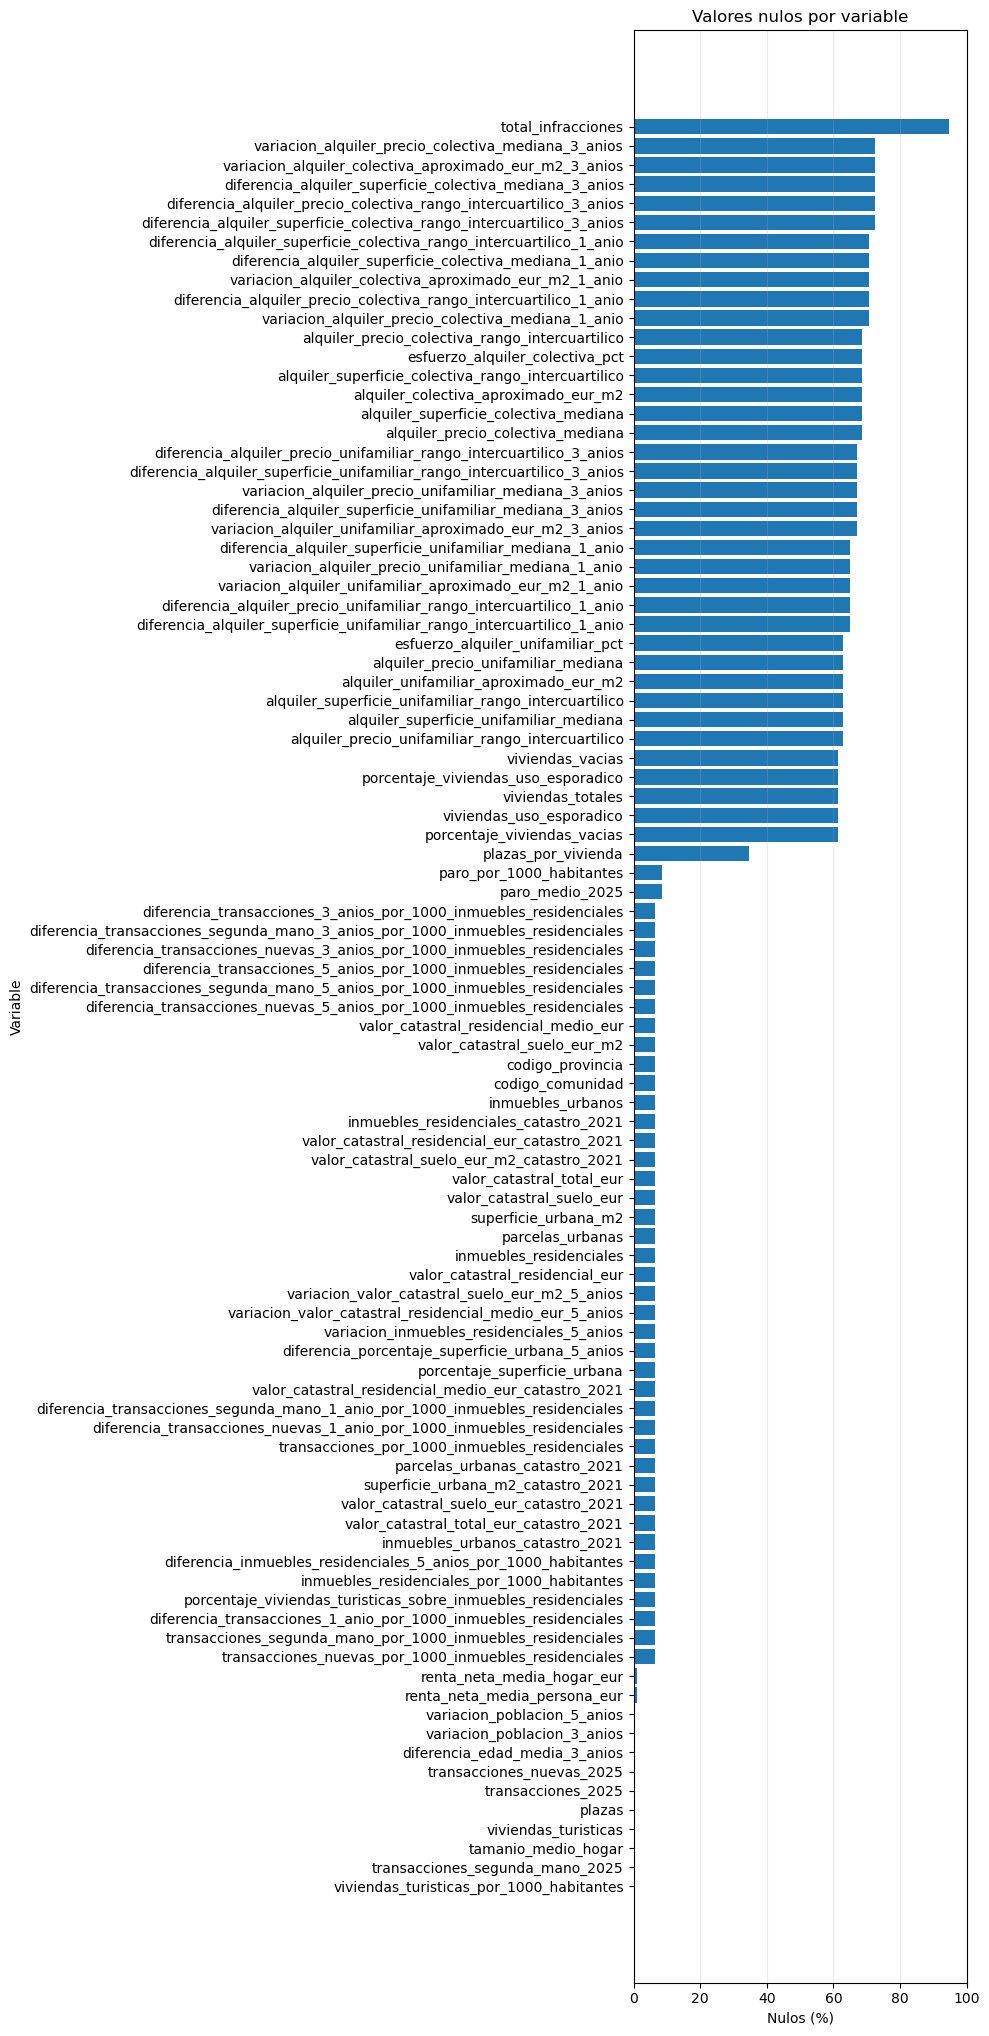

In [43]:
# Visualización de variables con algún valor nulo
plot_nulos = nulos.query('nulos > 0').sort_values('nulos_pct')

fig, ax = plt.subplots(figsize=(10, max(6, len(plot_nulos) * 0.22)))
ax.barh(plot_nulos.index.astype(str), plot_nulos['nulos_pct'])
ax.set(title='Valores nulos por variable', xlabel='Nulos (%)', ylabel='Variable')
ax.set_xlim(0, 100)
ax.grid(axis='x', alpha=0.25)
fig.tight_layout()
plt.show()

La variable total_infracciones muestra un elevado porcentaje de valores nulos (aprox 95%), por lo que se descarta su uso para la segmentación.

### Cobertura de fuentes clave

En la siguiente tabla se muestra un resumen de la cobertura de varias variables procendentes de distintas fuentes de datos. Esta información nos apoyará la toma de decisiones acerca de las variables que se utilizarán posteriormente en el clustering a nivel nacional.

In [45]:
variables_cobertura = {
    'edad': 'edad_media_2025',
    'renta': 'renta_neta_media_persona_eur',
    'catastro': 'inmuebles_residenciales',
    'paro': 'paro_por_1000_habitantes',
    'viviendas': 'viviendas_totales',
    'alquiler_colectiva': 'alquiler_precio_colectiva_mediana',
    'alquiler_unifamiliar': 'alquiler_precio_unifamiliar_mediana',
    'criminalidad': 'total_infracciones',
}
variables_cobertura = {k: v for k, v in variables_cobertura.items() if v in df.columns}

cobertura = pd.DataFrame([
    {
        'fuente': fuente,
        'variable_representativa': columna,
        'municipios_con_dato': int(df[columna].notna().sum()),
        'cobertura_pct': float(df[columna].notna().mean() * 100),
    }
    for fuente, columna in variables_cobertura.items()
]).sort_values('cobertura_pct', ascending=False)

display(cobertura.round(2))

,fuente,variable_representativa,municipios_con_dato,cobertura_pct
0,edad,edad_media_2025,8132,100.00
1,renta,renta_neta_media_persona_eur,8059,99.10
2,catastro,inmuebles_residenciales,7606,93.53
3,paro,paro_por_1000_habitantes,7430,91.37
4,viviendas,viviendas_totales,3139,38.60
6,alquiler_unifamiliar,alquiler_precio_unifamiliar_mediana,3020,37.14
5,alquiler_colectiva,alquiler_precio_colectiva_mediana,2555,31.42
7,criminalidad,total_infracciones,427,5.25


### Catastro y patrón territorial

Analicemos ahora la relación existente entre las provincias y los valores nulos existentes en las variables procedentes del catastro.

,municipios,municipios_sin_catastro,porcentaje_sin_catastro
provincia,,,
Navarra,272,272,100.00
Bizkaia,113,113,100.00
Gipuzkoa,88,88,100.00
Araba/Álava,51,51,100.00
Pontevedra,61,1,1.64
A Coruña,93,1,1.08
Alacant/Alicante,141,0,0.00
Albacete,87,0,0.00
Almería,103,0,0.00


Municipios sin Catastro: 526
Provincias con algún municipio sin Catastro: 6


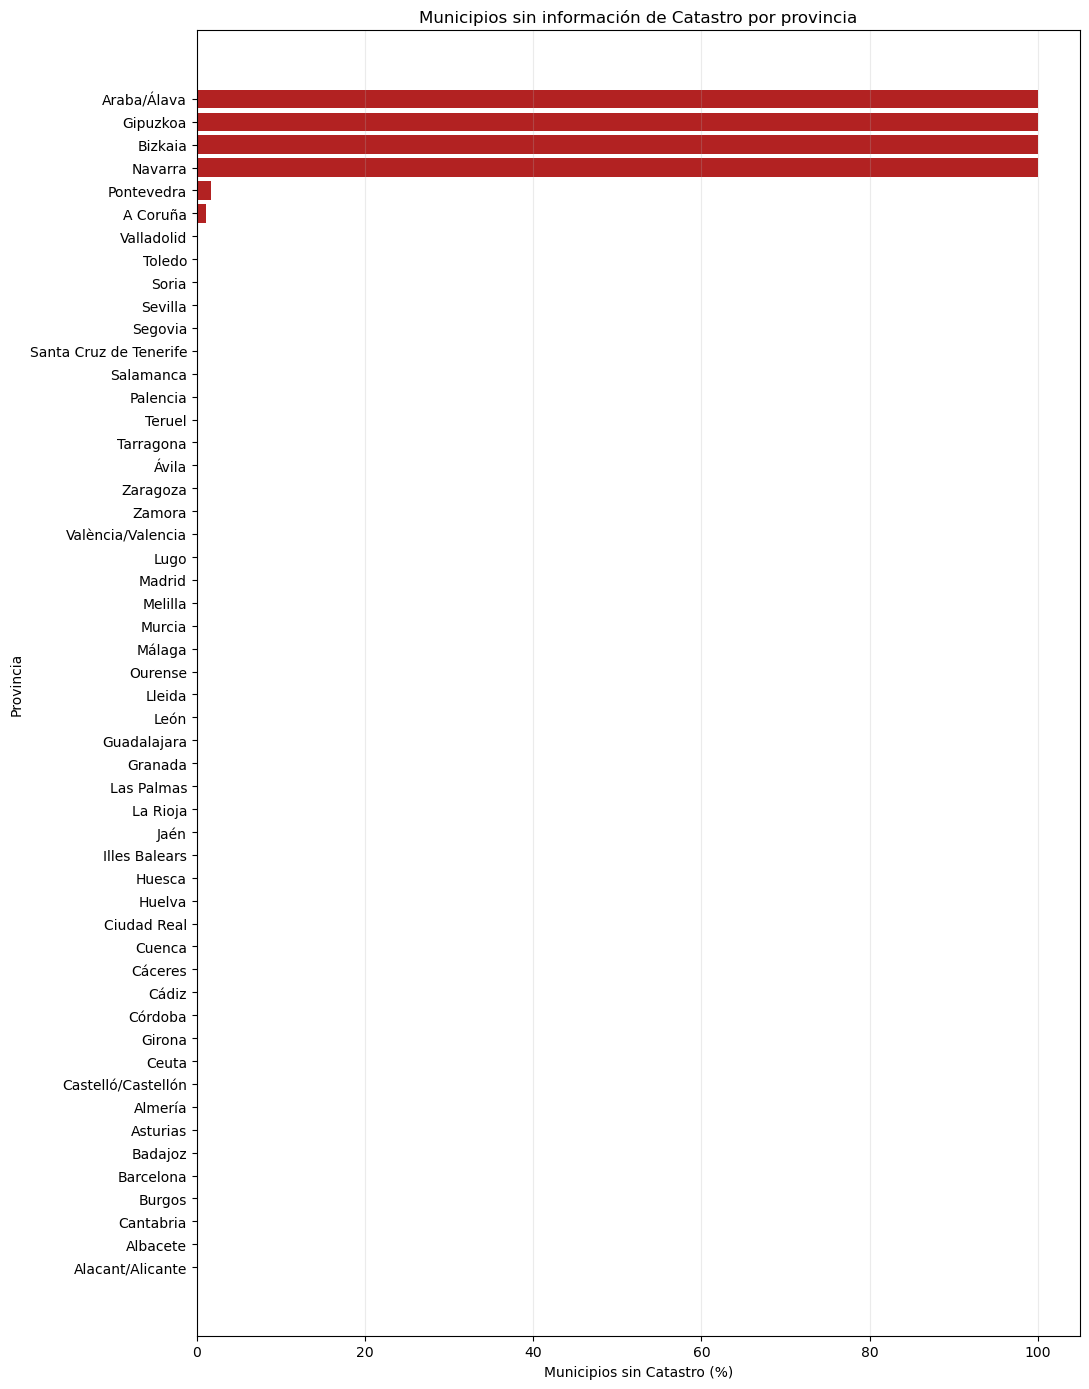

In [16]:
catastro_por_provincia = (
    df.assign(catastro_nulo=df['inmuebles_residenciales'].isna())
    .groupby('provincia', dropna=False)
    .agg(
        municipios=('codigo_ine', 'size'),
        municipios_sin_catastro=('catastro_nulo', 'sum'),
    )
    .assign(
        porcentaje_sin_catastro=lambda x: (
            x['municipios_sin_catastro'].div(x['municipios']).mul(100).round(2)
        )
    )
    .sort_values(
        ['porcentaje_sin_catastro', 'municipios_sin_catastro'],
        ascending=False,
    )
)

display(catastro_por_provincia)

provincias_con_nulos_catastro = catastro_por_provincia.query(
    'municipios_sin_catastro > 0'
)
print(
    f'Municipios sin Catastro: '
    f'{catastro_por_provincia["municipios_sin_catastro"].sum():,}'
)
print(
    f'Provincias con algún municipio sin Catastro: '
    f'{len(provincias_con_nulos_catastro)}'
)

datos_grafico = catastro_por_provincia.sort_values(
    'porcentaje_sin_catastro', ascending=True
)
colores = np.where(
    datos_grafico['porcentaje_sin_catastro'].gt(0),
    'firebrick',
    'lightgray',
)

fig, ax = plt.subplots(figsize=(11, 14))
ax.barh(
    datos_grafico.index.astype(str),
    datos_grafico['porcentaje_sin_catastro'],
    color=colores,
)
ax.set(
    title='Municipios sin información de Catastro por provincia',
    xlabel='Municipios sin Catastro (%)',
    ylabel='Provincia',
)
ax.set_xlim(0, 105)
ax.grid(axis='x', alpha=0.25)
fig.tight_layout()
plt.show()

Como ya sabíamos, el catastro no cubre los municipios de las comunidades de Navarra y País Vasco. Por otra parte, no se aprecian apenas valores nulos para el resto del territorio nacional. Por este motivo y debido a la fuerte relevancia en este trabajo de las variables del Catastro, **se ha optado por excluir el País Vasco y Navarra del objeto de estudio en la presente segmentación del mercado inmobiliario español**.

### Alquiler y tamaño municipal

Estudiemos la cobertura conjunta de las variables de alquiler para distintos umbrales de población municipal.

,variable,situacion,municipios,poblacion_mediana,poblacion_p25,poblacion_p75,poblacion_media
0,Alquiler colectivo,Sin dato,5577,238.0,99.0,594.0,511.5
1,Alquiler colectivo,Con dato,2555,5150.0,2288.0,12779.5,18106.3
2,Alquiler unifamiliar,Sin dato,5112,206.0,91.0,492.0,516.1
3,Alquiler unifamiliar,Con dato,3020,3803.0,1658.2,10044.0,15389.5


,tramo_poblacion,municipios,Alquiler colectivo_nulos_pct,Alquiler unifamiliar_nulos_pct
0,≤ 500,3987,98.90,96.79
1,501–1.000,994,85.51,72.13
2,1.001–5.000,1826,41.62,26.56
3,5.001–10.000,542,4.43,4.98
4,10.001–50.000,630,0.00,3.81
5,50.001–100.000,86,0.00,0.00
6,> 100.000,67,0.00,0.00


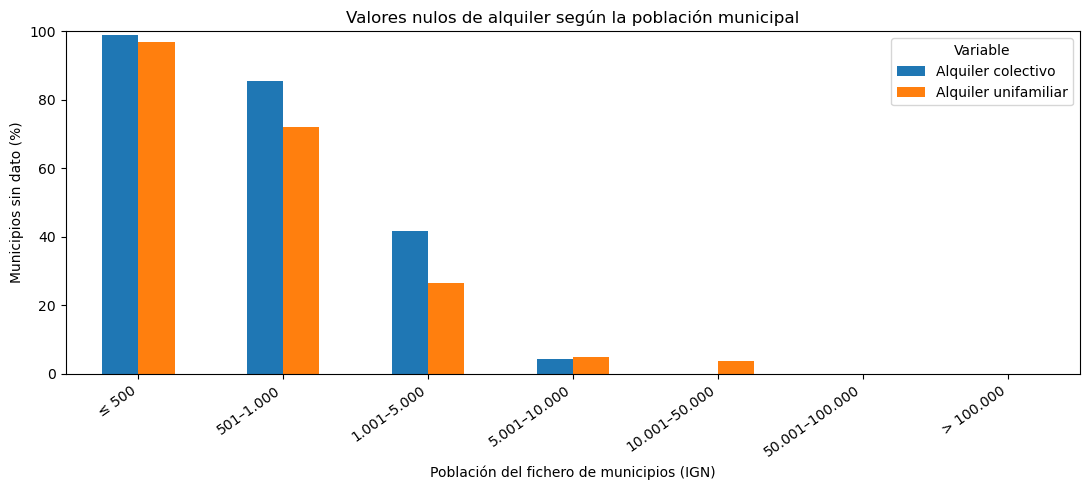

In [47]:
variables_alquiler = {
    'Alquiler colectivo': 'alquiler_precio_colectiva_mediana',
    'Alquiler unifamiliar': 'alquiler_precio_unifamiliar_mediana',
}
columna_poblacion = 'poblacion_2025'

# Agrupamos los municipios en función de si las variables de alquiler son nulas o no
resumen_poblacion_nulos = []
for fuente, columna in variables_alquiler.items():
    for tiene_dato, grupo in df.groupby(df[columna].notna()):
        poblacion = grupo[columna_poblacion].dropna()
        resumen_poblacion_nulos.append({
            'variable': fuente,
            'situacion': 'Con dato' if tiene_dato else 'Sin dato',
            'municipios': len(grupo),
            'poblacion_mediana': poblacion.median(),
            'poblacion_p25': poblacion.quantile(0.25),
            'poblacion_p75': poblacion.quantile(0.75),
            'poblacion_media': poblacion.mean(),
        })

resumen_poblacion_nulos = pd.DataFrame(resumen_poblacion_nulos)
display(resumen_poblacion_nulos.round(1))

limites_poblacion = [-np.inf, 500, 1_000, 5_000, 10_000, 50_000, 100_000, np.inf]
etiquetas_poblacion = [
    '≤ 500', '501–1.000', '1.001–5.000', '5.001–10.000',
    '10.001–50.000', '50.001–100.000', '> 100.000',
]
tramo_poblacion = pd.cut(
    df[columna_poblacion],
    bins=limites_poblacion,
    labels=etiquetas_poblacion,
    include_lowest=True,
)

nulos_por_poblacion = pd.DataFrame({'tramo_poblacion': tramo_poblacion})
for fuente, columna in variables_alquiler.items():
    nulos_por_poblacion[fuente] = df[columna].isna()

nulos_por_poblacion = (
    nulos_por_poblacion
    .groupby('tramo_poblacion', observed=False)
    .agg(
        municipios=('tramo_poblacion', 'size'),
        **{f'{fuente}_nulos_pct': (fuente, lambda serie: serie.mean() * 100)
           for fuente in variables_alquiler}
    )
    .reset_index()
)
display(nulos_por_poblacion.round(2))

columnas_nulos = [f'{fuente}_nulos_pct' for fuente in variables_alquiler]
ax = nulos_por_poblacion.set_index('tramo_poblacion')[columnas_nulos].plot.bar(
    figsize=(11, 5),
)
ax.set_title('Valores nulos de alquiler según la población municipal')
ax.set_xlabel('Población del fichero de municipios (IGN)')
ax.set_ylabel('Municipios sin dato (%)')
ax.set_ylim(0, 100)
ax.legend(['Alquiler colectivo', 'Alquiler unifamiliar'], title='Variable')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

Como se puede observar en el gráfico, los municipios con menos habitantes presentan un gran porcentaje de valores nulos en variables relacionadas con el alquiler, y este porcentaje de valores nulos disminuye conforme aumenta la población del municipio.

### Viviendas y tamaño municipal

Analizaremos ahora la cobertura conjunta de variables relacionadas con el uso de la vivienda para distintos umbrales de población municipal.

,variable,situacion,municipios,poblacion_mediana,poblacion_p25,poblacion_p75,poblacion_media
0,Viviendas totales,Sin dato,4993,196.0,89.0,432.0,290.4
1,Viviendas totales,Con dato,3139,3857.0,1861.0,9972.0,15184.6
2,Viviendas vacías,Sin dato,4993,196.0,89.0,432.0,290.4
3,Viviendas vacías,Con dato,3139,3857.0,1861.0,9972.0,15184.6
4,Viviendas de uso esporádico,Sin dato,4993,196.0,89.0,432.0,290.4
5,Viviendas de uso esporádico,Con dato,3139,3857.0,1861.0,9972.0,15184.6
6,Porcentaje de viviendas vacías,Sin dato,4993,196.0,89.0,432.0,290.4
7,Porcentaje de viviendas vacías,Con dato,3139,3857.0,1861.0,9972.0,15184.6
8,Porcentaje de uso esporádico,Sin dato,4993,196.0,89.0,432.0,290.4
9,Porcentaje de uso esporádico,Con dato,3139,3857.0,1861.0,9972.0,15184.6


,tramo_poblacion,municipios,Viviendas totales_nulos_pct,Viviendas vacías_nulos_pct,Viviendas de uso esporádico_nulos_pct,Porcentaje de viviendas vacías_nulos_pct,Porcentaje de uso esporádico_nulos_pct
0,≤ 500,3987,100.00,100.00,100.00,100.00,100.00
1,501–1.000,994,97.59,97.59,97.59,97.59,97.59
2,1.001–5.000,1826,1.97,1.97,1.97,1.97,1.97
3,5.001–10.000,542,0.00,0.00,0.00,0.00,0.00
4,10.001–50.000,630,0.00,0.00,0.00,0.00,0.00
5,50.001–100.000,86,0.00,0.00,0.00,0.00,0.00
6,> 100.000,67,0.00,0.00,0.00,0.00,0.00


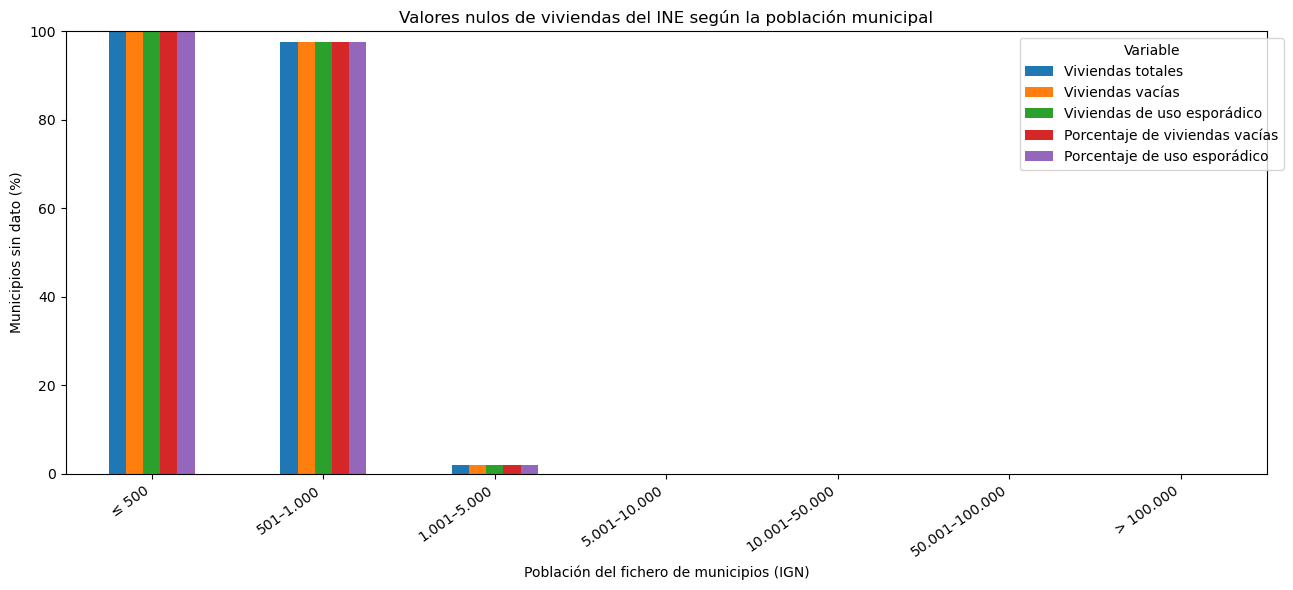

In [49]:
variables_viviendas_ine = {
    'Viviendas totales': 'viviendas_totales',
    'Viviendas vacías': 'viviendas_vacias',
    'Viviendas de uso esporádico': 'viviendas_uso_esporadico',
    'Porcentaje de viviendas vacías': 'porcentaje_viviendas_vacias',
    'Porcentaje de uso esporádico': 'porcentaje_viviendas_uso_esporadico',
}
columna_poblacion = 'poblacion_2025'

# Agrupamos los municipios en función de si las variables de vivienda son nulas o no
resumen_poblacion_nulos_viviendas = []
for variable, columna in variables_viviendas_ine.items():
    for tiene_dato, grupo in df.groupby(df[columna].notna()):
        poblacion = grupo[columna_poblacion].dropna()
        resumen_poblacion_nulos_viviendas.append({
            'variable': variable,
            'situacion': 'Con dato' if tiene_dato else 'Sin dato',
            'municipios': len(grupo),
            'poblacion_mediana': poblacion.median(),
            'poblacion_p25': poblacion.quantile(0.25),
            'poblacion_p75': poblacion.quantile(0.75),
            'poblacion_media': poblacion.mean(),
        })

resumen_poblacion_nulos_viviendas = pd.DataFrame(
    resumen_poblacion_nulos_viviendas
)
display(resumen_poblacion_nulos_viviendas.round(1))

limites_poblacion_viviendas = [
    -np.inf, 500, 1_000, 5_000, 10_000, 50_000, 100_000, np.inf
]
etiquetas_poblacion_viviendas = [
    '≤ 500', '501–1.000', '1.001–5.000', '5.001–10.000',
    '10.001–50.000', '50.001–100.000', '> 100.000',
]
tramo_poblacion_viviendas = pd.cut(
    df[columna_poblacion],
    bins=limites_poblacion_viviendas,
    labels=etiquetas_poblacion_viviendas,
    include_lowest=True,
)

nulos_viviendas_por_poblacion = pd.DataFrame({
    'tramo_poblacion': tramo_poblacion_viviendas,
})
for variable, columna in variables_viviendas_ine.items():
    nulos_viviendas_por_poblacion[variable] = df[columna].isna()

nulos_viviendas_por_poblacion = (
    nulos_viviendas_por_poblacion
    .groupby('tramo_poblacion', observed=False)
    .agg(
        municipios=('tramo_poblacion', 'size'),
        **{f'{variable}_nulos_pct': (
               variable, lambda serie: serie.mean() * 100
           ) for variable in variables_viviendas_ine}
    )
    .reset_index()
)
display(nulos_viviendas_por_poblacion.round(2))

columnas_nulos_viviendas = [
    f'{variable}_nulos_pct' for variable in variables_viviendas_ine
]
ax = nulos_viviendas_por_poblacion.set_index('tramo_poblacion')[
    columnas_nulos_viviendas
].plot.bar(figsize=(13, 6))
ax.set_title('Valores nulos de viviendas del INE según la población municipal')
ax.set_xlabel('Población del fichero de municipios (IGN)')
ax.set_ylabel('Municipios sin dato (%)')
ax.set_ylim(0, 100)
ax.legend(list(variables_viviendas_ine), title='Variable', bbox_to_anchor=(1.02, 1))
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

Estamos ante un caso prácticamente idéntico al de las variables de alquiler. Para los municipios de menos de 1.000 habitantes apenas se han recogido datos, mientras que para los municipios con mayor número de habitantes el porcentaje de valores nulos es 0.

Ante esta situación, se ha tomado la decisión de realizar dos segmentaciones distintas: una segmentación más general de todos los municipios españoles (salvo Navarra y País Vasco) y otra más específica en la que incluiremos solamente aquellos municipios que tengan una población mayor a un umbral que decidiremos más adelante.

De esta manera, podremos hacer foco en los municipios más relevantes a nivel nacional y realizar una clusterización teniendo en cuenta más variables relevantes para el sector inmobiliario, facilitando así la detección de patrones.

## Estadísticos descriptivos y escala

Para clustering, es importante tener en cuenta las diferencias de escala entre las distintas variables. Identificaremos órdenes de magnitud, colas largas y variables susceptibles de requerir alguna transformación o escalado robusto.

In [52]:
descripcion = df.select_dtypes(include=np.number).describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).T

# Calculamos el rango y el rango intercuartílico como medidas adicionales de dispersión
descripcion['rango'] = descripcion['max'] - descripcion['min']
descripcion['iqr'] = descripcion['75%'] - descripcion['25%']

display(descripcion.sort_values('std', ascending=False))

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,rango,iqr
valor_catastral_total_eur,7606.0,3.196876e+08,3.920752e+09,285959.14,977118.5775,1.971236e+06,6.659404e+06,2.285557e+07,1.029649e+08,1.010893e+09,4.893058e+09,2.994801e+11,2.994798e+11,9.630554e+07
valor_catastral_suelo_eur,7606.0,1.579741e+08,2.655543e+09,22230.24,95903.9285,2.339442e+05,1.154868e+06,5.567086e+06,3.246638e+07,4.362526e+08,2.432200e+09,2.097232e+11,2.097232e+11,3.131151e+07
valor_catastral_residencial_eur,7606.0,2.068537e+08,2.423837e+09,138275.12,631704.8000,1.393158e+06,4.854330e+06,1.615952e+07,7.002768e+07,6.651192e+08,3.162390e+09,1.831063e+11,1.831061e+11,6.517335e+07
superficie_urbana_m2,7606.0,1.381313e+06,4.583473e+06,5463.00,16287.8500,3.068325e+04,1.016250e+05,2.873315e+05,1.060934e+06,6.111827e+06,1.574186e+07,2.370006e+08,2.369951e+08,9.593090e+05
poblacion_2025,8132.0,6.039657e+03,5.039679e+04,6.00,19.0000,4.000000e+01,1.500000e+02,5.260000e+02,2.460000e+03,2.095730e+04,8.915713e+04,3.506730e+06,3.506724e+06,2.310000e+03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
diferencia_edad_media_3_anios,8131.0,3.407625e-01,1.740105e+00,-17.42,-5.5820,-2.510000e+00,-2.100000e-01,5.200000e-01,1.090000e+00,2.525000e+00,4.387000e+00,2.296000e+01,4.038000e+01,1.300000e+00
alquiler_unifamiliar_aproximado_eur_m2,3020.0,3.046917e+00,1.410704e+00,0.61,1.0900,1.370000e+00,2.050000e+00,2.750000e+00,3.700000e+00,5.610000e+00,7.700000e+00,1.209000e+01,1.148000e+01,1.650000e+00
diferencia_edad_media_1_anio,8132.0,1.236805e-01,1.020344e+00,-15.63,-3.1200,-1.420000e+00,-1.800000e-01,2.000000e-01,4.700000e-01,1.440000e+00,2.766900e+00,2.072000e+01,3.635000e+01,6.500000e-01
diferencia_porcentaje_superficie_urbana_5_anios,7606.0,4.603077e-02,6.508595e-01,-18.60,-0.5800,-7.750000e-02,0.000000e+00,-0.000000e+00,1.000000e-02,2.000000e-01,1.637000e+00,1.504000e+01,3.364000e+01,1.000000e-02


## Asimetría y transformaciones candidatas

Como se analizó previamente con Athena en los conjuntos de datos procesados, las distribuciones del paro, los movimientos migratorios y ciertas variables monetarias presentaban una fuerte asimetría a la derecha.

A continuación analizaremos la asimetría presente en las variables numéricas de cara a realizar más adelante transformaciones logarítmicas o aplicar escalados.

In [53]:
numeric_clean = df.select_dtypes(include=np.number).replace([np.inf, -np.inf], np.nan)
asimetria = numeric_clean.skew().sort_values(key=abs, ascending=False).to_frame('asimetria')
asimetria['abs_asimetria'] = asimetria['asimetria'].abs()
asimetria['min'] = numeric_clean.min()

# Consideraremos que una variable es candidata a aplicar una transformación logarítmica
# cuando presente una gran asimetría y no tenga valores negativos.
asimetria['candidata_log1p'] = (asimetria['abs_asimetria'] > 1) & (asimetria['min'] >= 0)

display(asimetria.head(40))

,asimetria,abs_asimetria,min,candidata_log1p
valor_catastral_suelo_eur,68.511422,68.511422,22230.24,True
valor_catastral_total_eur,62.928071,62.928071,285959.14,True
valor_catastral_residencial_eur,61.526758,61.526758,138275.12,True
saldo_exterior,53.551164,53.551164,-278.00,False
saldo_interior,-51.898673,51.898673,-18722.00,False
saldo_total,49.871917,49.871917,-945.00,False
poblacion_2025,48.263700,48.263700,6.00,True
poblacion_ign,47.795760,47.795760,2.00,True
transacciones_segunda_mano_2025,45.035211,45.035211,0.00,True
inmuebles_residenciales,44.874707,44.874707,5.00,True


Representaremos ahora histogramas de estas variables numéricas.

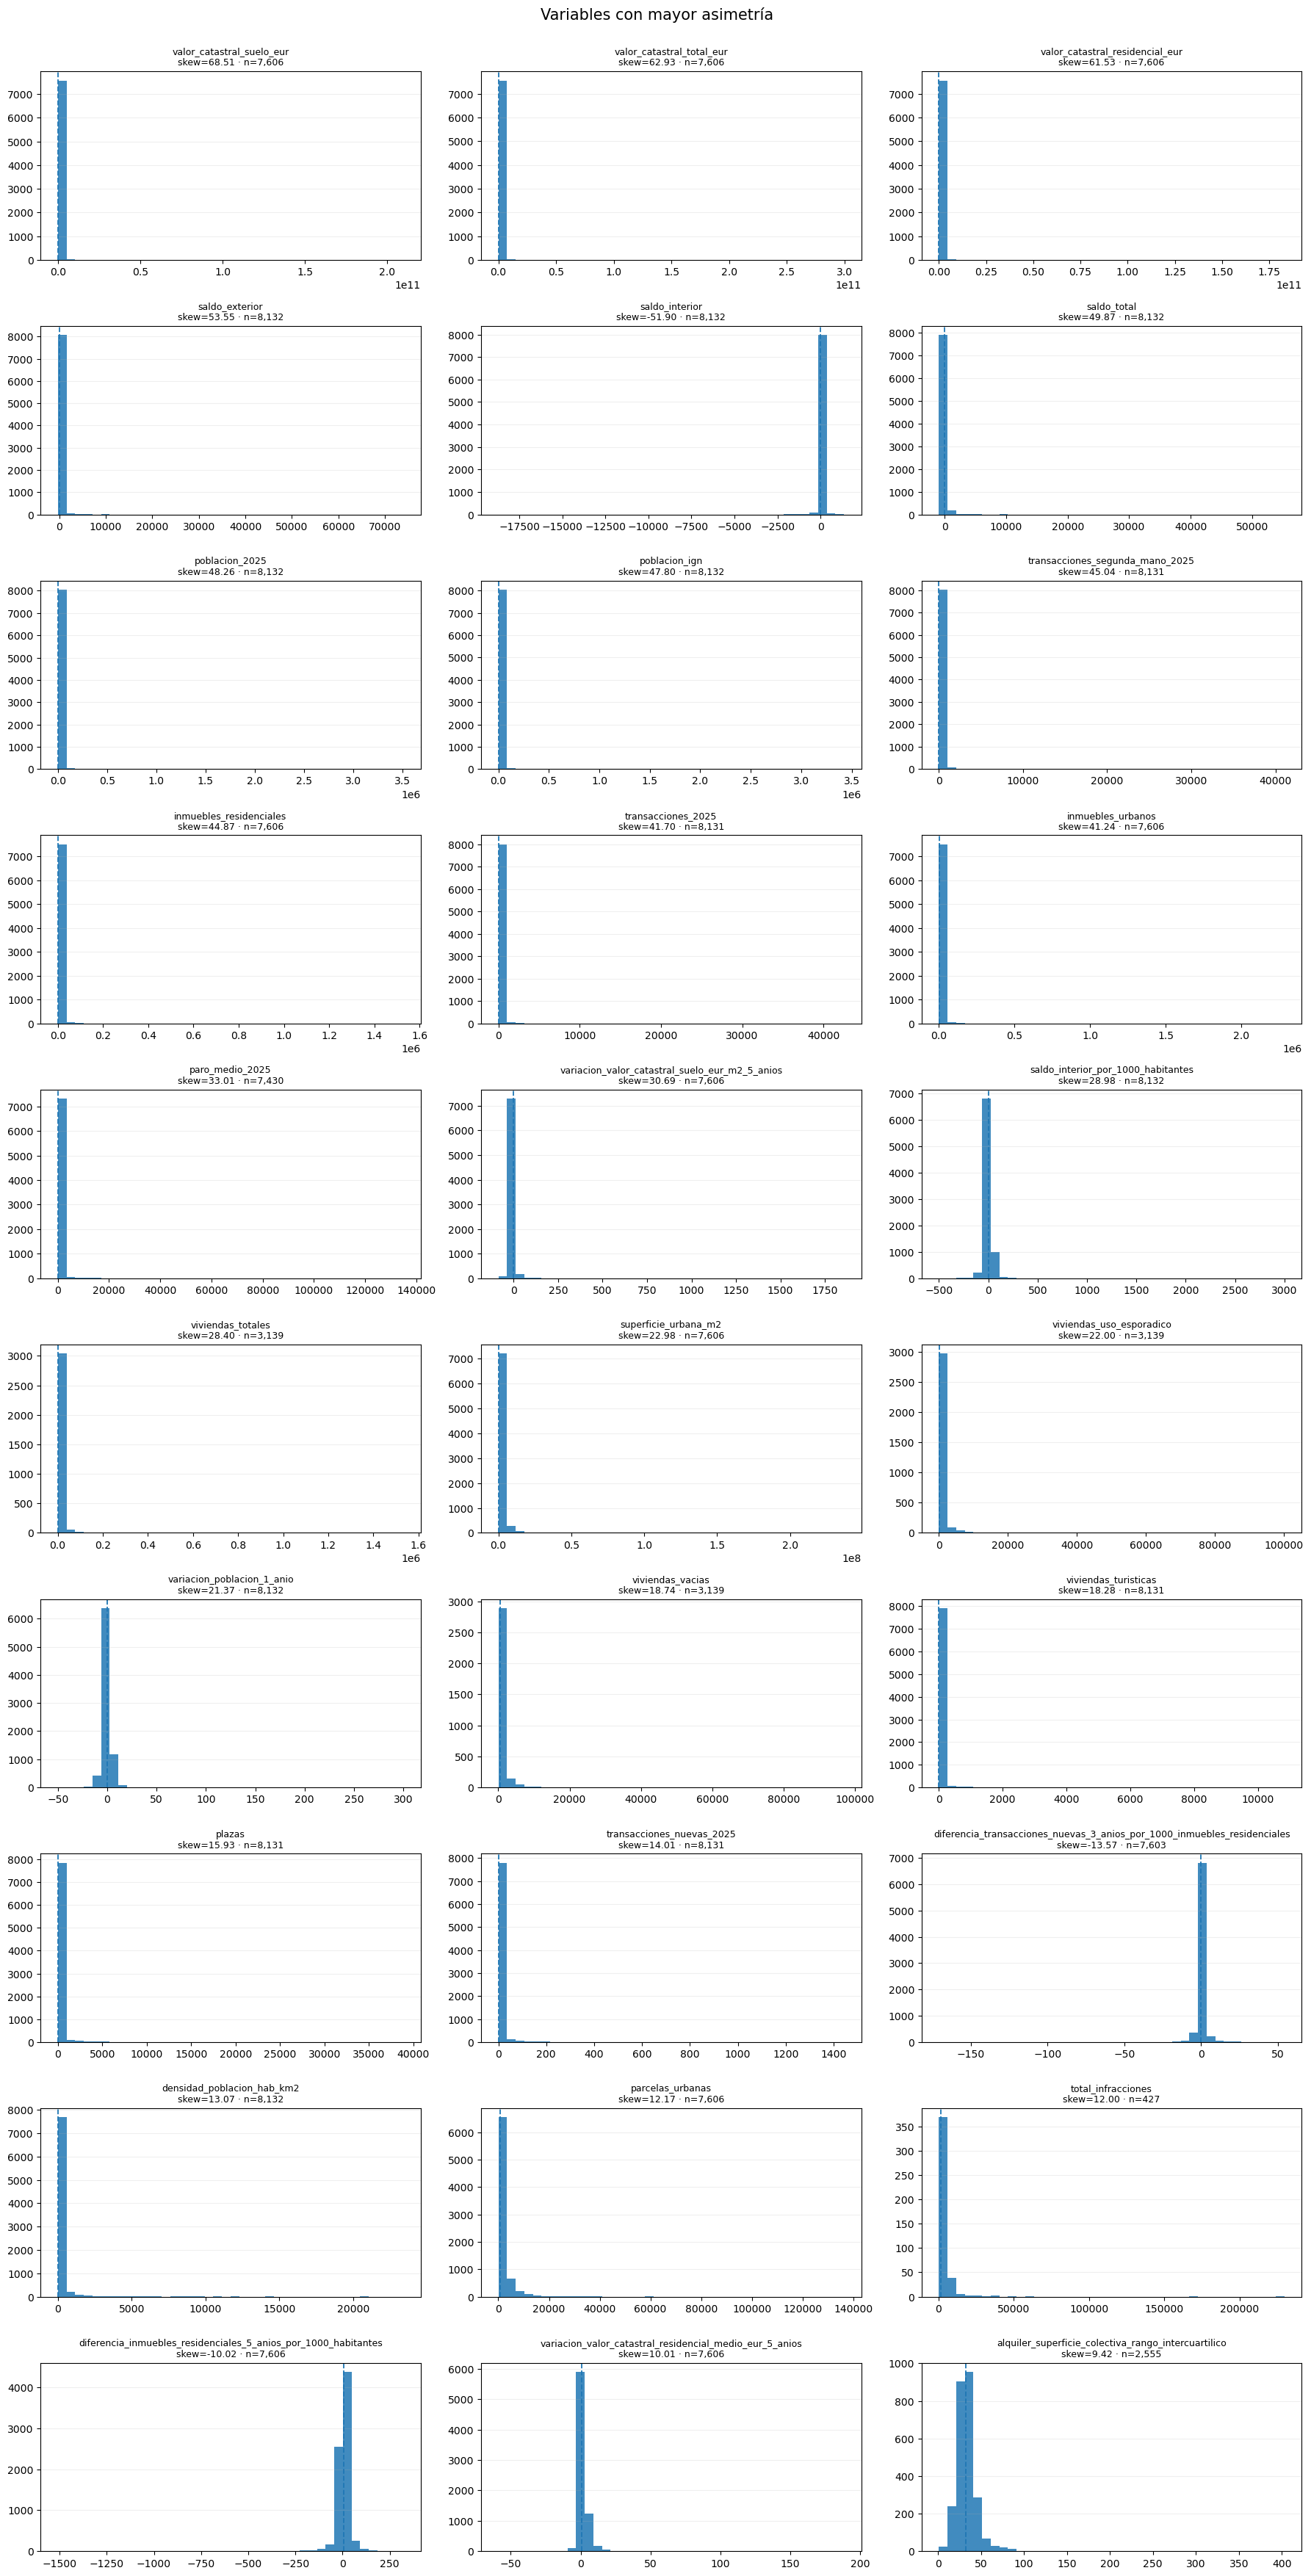

In [54]:
variables_asimetricas = asimetria.head(min(30, len(asimetria))).index.tolist()
ncols = 3
nrows = int(np.ceil(len(variables_asimetricas) / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(18, nrows * 3.5))
axes = np.atleast_1d(axes).ravel()

for ax, variable in zip(axes, variables_asimetricas):
    valores = numeric_clean[variable].dropna().astype(float)
    if valores.empty:
        ax.set_visible(False)
        continue
    ax.hist(valores, bins=40, alpha=0.85)
    ax.axvline(valores.median(), linestyle='--', linewidth=1.3, label='Mediana')
    ax.set_title(f'{variable}\nskew={asimetria.loc[variable, "asimetria"]:.2f} · n={len(valores):,}', fontsize=9)
    ax.grid(axis='y', alpha=0.2)

for ax in axes[len(variables_asimetricas):]:
    ax.set_visible(False)

fig.suptitle('Variables con mayor asimetría', y=1.001, fontsize=15)
fig.tight_layout()
plt.show()

Como se puede observar, estas variables están mayormente concentradas en torno a la mediana salvo ciertos valores extremos.

Dibujemos ahora los mismos histogramas restringiéndonos a los valores entre el percentil 1 y el percentil 99 para eliminar el efecto de los valores más extremos.

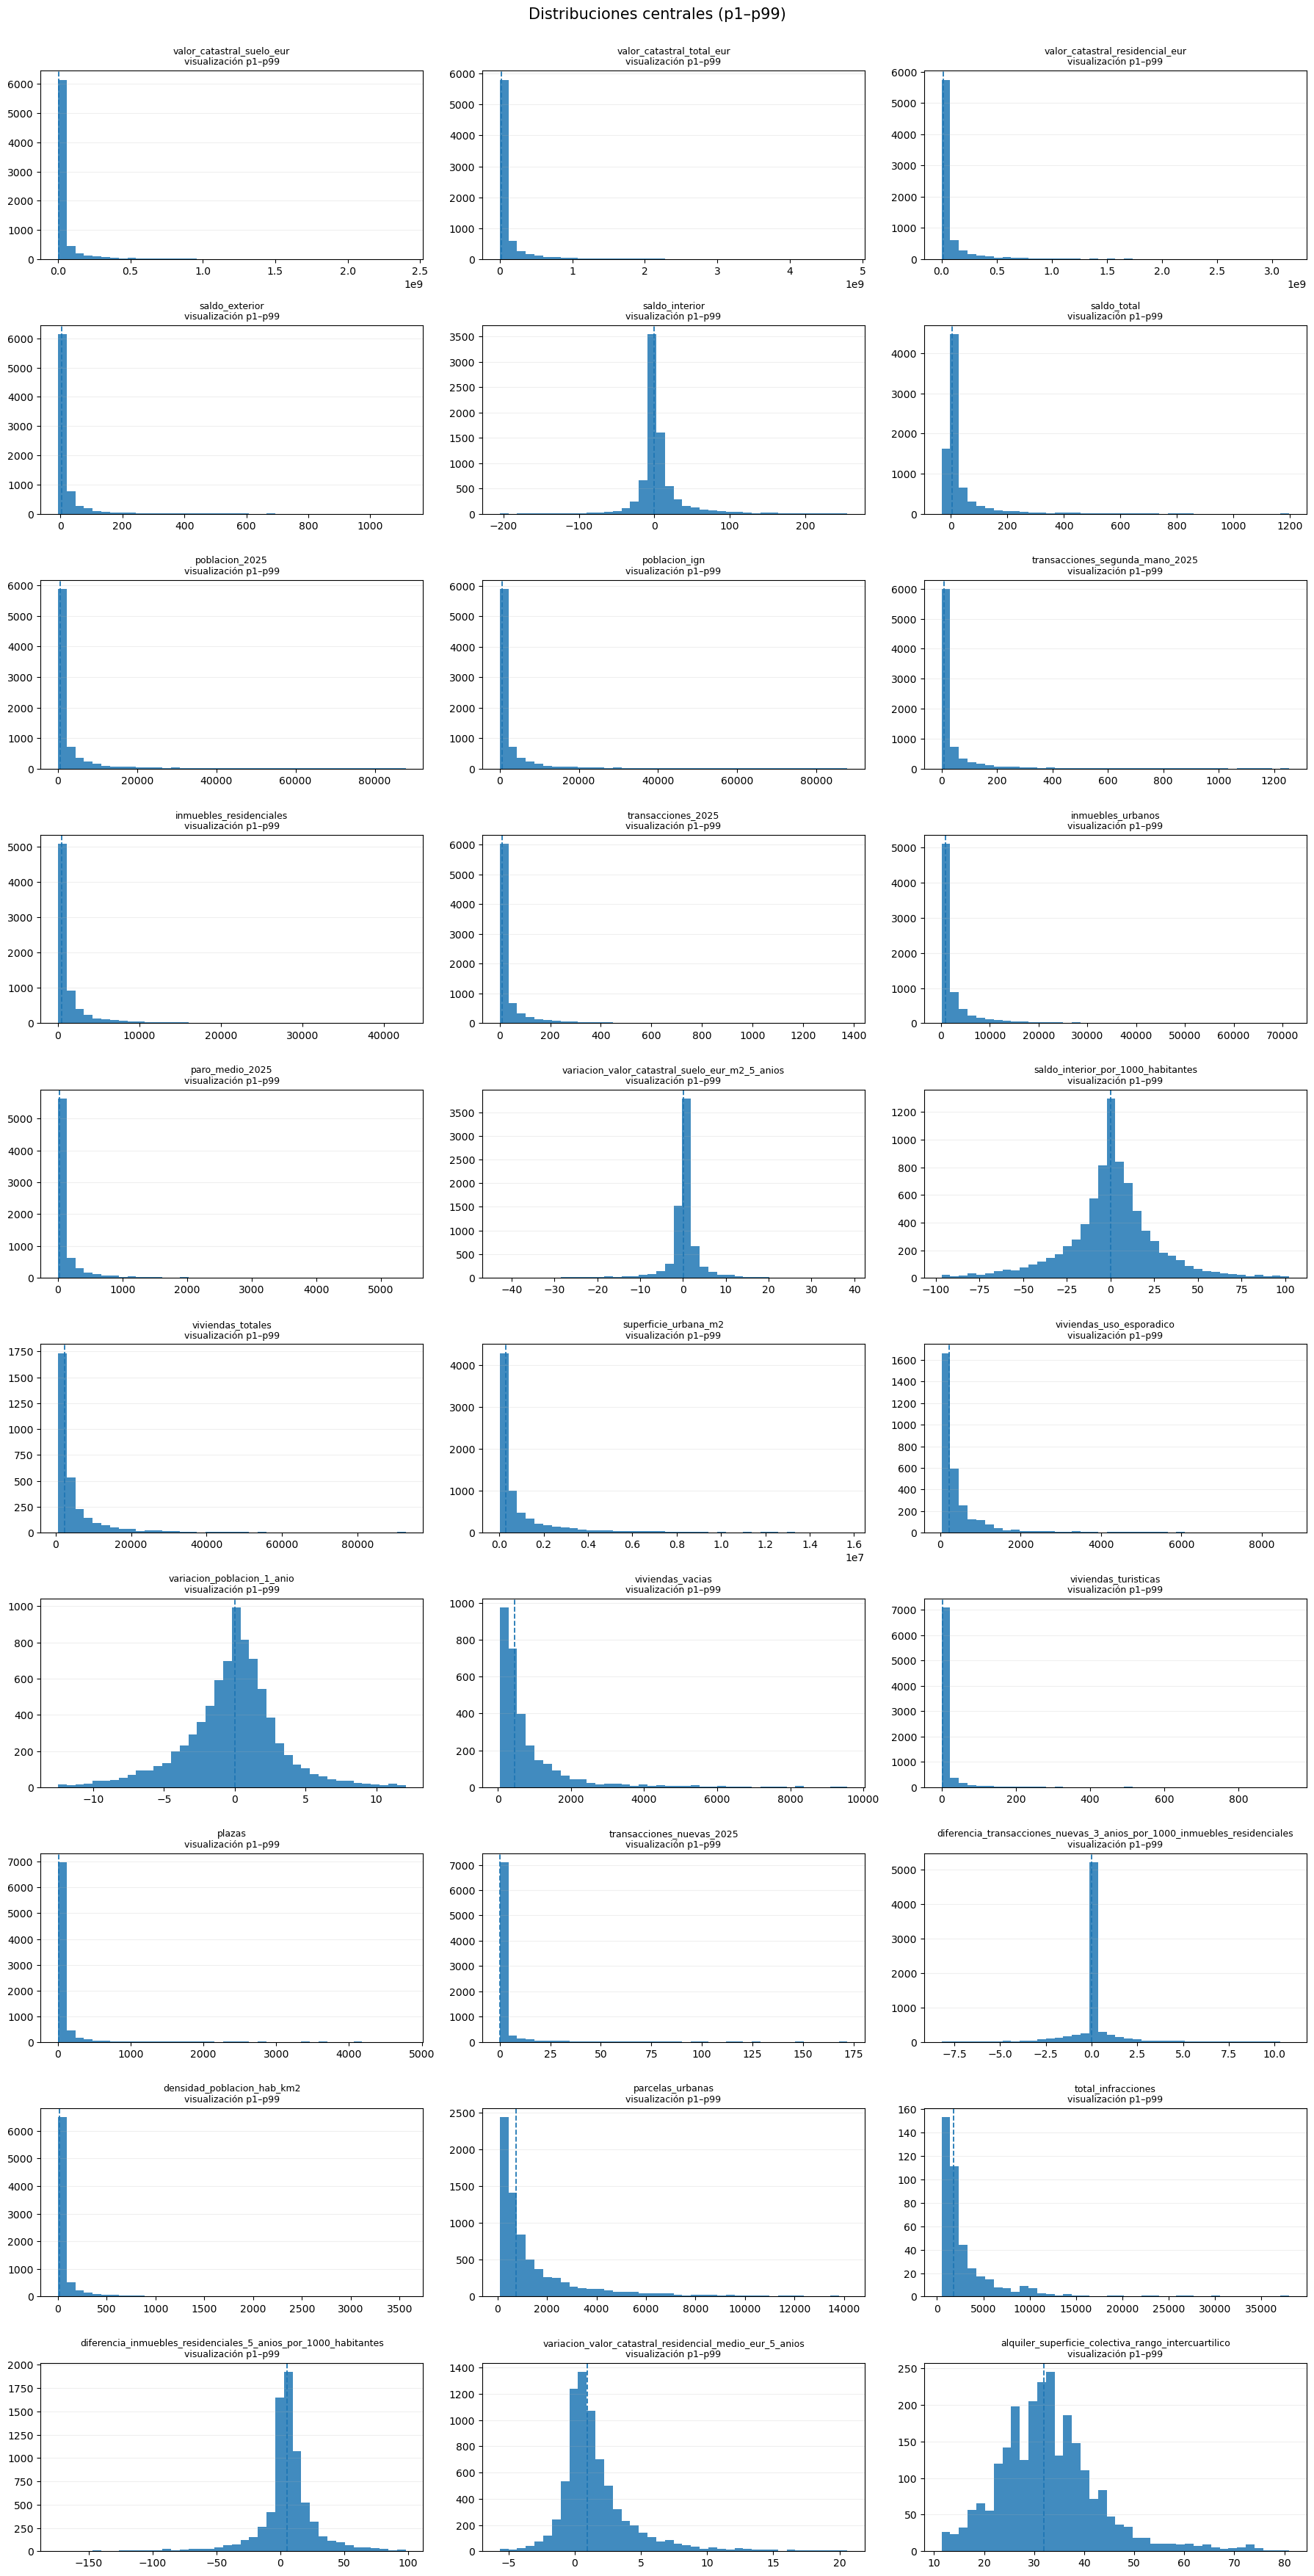

In [55]:
# Mismos histogramas limitando únicamente la visualización a percentil1 – percentil 99.
fig, axes = plt.subplots(nrows, ncols, figsize=(18, nrows * 3.5))
axes = np.atleast_1d(axes).ravel()

for ax, variable in zip(axes, variables_asimetricas):
    valores = numeric_clean[variable].dropna().astype(float)
    if valores.empty:
        ax.set_visible(False)
        continue
    q01, q99 = valores.quantile([0.01, 0.99])
    centrales = valores[valores.between(q01, q99)]
    ax.hist(centrales, bins=40, alpha=0.85)
    ax.axvline(valores.median(), linestyle='--', linewidth=1.3, label='Mediana')
    ax.set_title(f'{variable}\nvisualización p1–p99', fontsize=9)
    ax.grid(axis='y', alpha=0.2)

for ax in axes[len(variables_asimetricas):]:
    ax.set_visible(False)

fig.suptitle('Distribuciones centrales (p1–p99)', y=1.001, fontsize=15)
fig.tight_layout()
plt.show()

Se observa que reducimos la asimetría en gran medida de algunas de estas variables al eliminar el efecto de los valores extremos.

## Valores extremos

Un municipio con valores extremos puede ser información real y no un error. Madrid, Barcelona, municipios costeros turísticos o localidades con muy poca población pueden presentar valores extremos con frecuencia.

Por ello, se cuantificarán los outliers mediante la regla IQR (aquellos que distan 1,5 veces el rango intercuartílico de Q1 o Q3, según corresponda) pero no eliminaremos ninguno de estos valores.

In [59]:
numericas = df.select_dtypes(include=np.number).columns.tolist()
# consideraremos en este análisis exploratorio a aquellos valores 
OUTLIER_IQR_FACTOR = 1.5 


def iqr_outlier_summary(series: pd.Series, factor: float = 1.5) -> dict:
    s = pd.to_numeric(series, errors='coerce').replace([np.inf, -np.inf], np.nan).dropna()
    if len(s) < 4:
        return {'n': len(s), 'outliers': 0, 'outliers_pct': 0.0, 'lim_inf': np.nan, 'lim_sup': np.nan}
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - factor * iqr, q3 + factor * iqr
    mask = (s < lo) | (s > hi)
    return {
        'n': len(s),
        'outliers': int(mask.sum()),
        'outliers_pct': float(mask.mean() * 100),
        'lim_inf': lo,
        'lim_sup': hi,
    }

outliers = pd.DataFrame({
    col: iqr_outlier_summary(df[col], OUTLIER_IQR_FACTOR)
    for col in numericas
}).T.sort_values('outliers_pct', ascending=False)

display(outliers.head(40).round(3))

,n,outliers,outliers_pct,lim_inf,lim_sup
diferencia_transacciones_nuevas_3_anios_por_1000_inmuebles_residenciales,7603.0,2545.0,33.474,0.000000e+00,0.000000e+00
diferencia_transacciones_nuevas_1_anio_por_1000_inmuebles_residenciales,7606.0,2529.0,33.250,0.000000e+00,0.000000e+00
diferencia_transacciones_nuevas_5_anios_por_1000_inmuebles_residenciales,7604.0,2502.0,32.904,0.000000e+00,0.000000e+00
diferencia_porcentaje_superficie_urbana_5_anios,7606.0,2142.0,28.162,-1.500000e-02,2.500000e-02
variacion_valor_catastral_suelo_eur_m2_5_anios,7606.0,1636.0,21.509,-2.691000e+00,3.339000e+00
saldo_interior,8132.0,1470.0,18.077,-2.600000e+01,3.000000e+01
transacciones_nuevas_por_1000_inmuebles_residenciales,7606.0,1305.0,17.158,-6.300000e-01,1.050000e+00
diferencia_inmuebles_residenciales_5_anios_por_1000_habitantes,7606.0,1253.0,16.474,-2.054600e+01,3.424400e+01
transacciones_nuevas_2025,8131.0,1309.0,16.099,-1.500000e+00,2.500000e+00
diferencia_alquiler_superficie_colectiva_rango_intercuartilico_1_anio,2391.0,382.0,15.977,-4.300000e+00,4.500000e+00


## Correlación y redundancia

Algunas de las variables recogidas en el dataset final pueden presentar una gran correlación entre ellas (por ejemplo, variaciones de 1, 3 y 5 años de una misma variable). Trataremos de eliminar más adelante aquellas variables que estén muy correlacionadas entre sí de cara al clustering.

Se utilizará **Spearman** porque es más robusta frente a asimetrías y relaciones monótonas no lineales. 

Variables presentes en revisión: 22


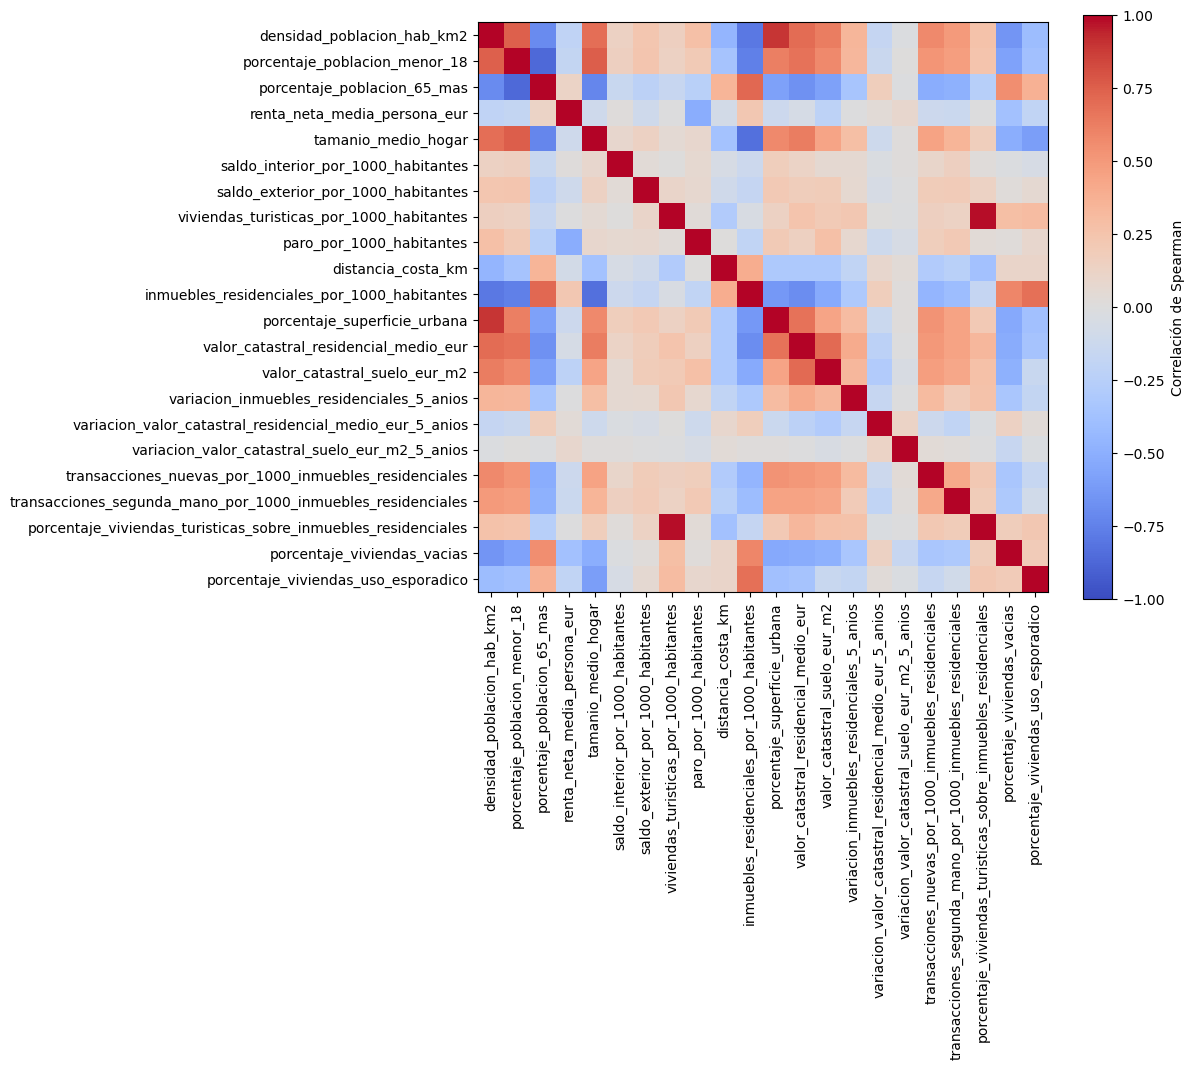

In [60]:
# Variables conceptualmente útiles para una primera revisión del modelo nacional.
variables_revision_preferidas = [
    'densidad_poblacion_hab_km2',
    'porcentaje_poblacion_menor_18',
    'porcentaje_poblacion_65_mas',
    'renta_neta_media_persona_eur',
    'tamanio_medio_hogar',
    'saldo_interior_por_1000_habitantes',
    'saldo_exterior_por_1000_habitantes',
    'viviendas_turisticas_por_1000_habitantes',
    'paro_por_1000_habitantes',
    'distancia_costa_km',
    'inmuebles_residenciales_por_1000_habitantes',
    'porcentaje_superficie_urbana',
    'valor_catastral_residencial_medio_eur',
    'valor_catastral_suelo_eur_m2',
    'variacion_inmuebles_residenciales_5_anios',
    'variacion_valor_catastral_residencial_medio_eur_5_anios',
    'variacion_valor_catastral_suelo_eur_m2_5_anios',
    'transacciones_nuevas_por_1000_inmuebles_residenciales',
    'transacciones_segunda_mano_por_1000_inmuebles_residenciales',
    'porcentaje_viviendas_turisticas_sobre_inmuebles_residenciales',
    'porcentaje_viviendas_vacias',
    'porcentaje_viviendas_uso_esporadico',
]

variables_revision = [c for c in variables_revision_preferidas if c in df.columns]
print(f'Variables presentes en revisión: {len(variables_revision)}')

corr = df[variables_revision].corr(method='spearman')

fig, ax = plt.subplots(figsize=(max(10, len(corr)*0.55), max(8, len(corr)*0.48)))
image = ax.imshow(corr, vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(len(corr)), corr.columns, rotation=90)
ax.set_yticks(range(len(corr)), corr.index)
fig.colorbar(image, ax=ax, label='Correlación de Spearman')
fig.tight_layout()
plt.show()

En el mapa de calor se aprecian ciertas variables que presentan una gran correlación entre ellas.

Ordenaremos ahora los pares de variables numéricas del dataset con mayor coeficiente de correlación de Spearman (en valor absoluto).

In [63]:
# Mostramos solo aquellas con un coef. de Spearman superior a 0.9
HIGH_CORR_THRESHOLD = 0.90

def high_correlation_pairs(data: pd.DataFrame, threshold: float = 0.90) -> pd.DataFrame:
    c = data.corr(method='spearman').abs()
    upper = c.where(np.triu(np.ones(c.shape), k=1).astype(bool))
    pairs = (
        upper.stack()
        .rename('abs_spearman')
        .reset_index()
        .rename(columns={'level_0': 'variable_1', 'level_1': 'variable_2'})
    )
    return pairs[pairs['abs_spearman'] >= threshold].sort_values('abs_spearman', ascending=False)

# Se excluyen de esta auditoría códigos e identificadores numéricos obvios.
id_tokens = ('codigo', 'id_', '_id', 'longitud', 'latitud')
numeric_for_corr = [
    c for c in numericas
    if not any(token in c.lower() for token in id_tokens)
]

redundancias = high_correlation_pairs(df[numeric_for_corr], HIGH_CORR_THRESHOLD)
display(redundancias.head(60))

,variable_1,variable_2,abs_spearman
19,poblacion_ign,poblacion_2025,0.999792
4222,transacciones_2025,transacciones_segunda_mano_2025,0.998805
382,valor_catastral_total_eur,valor_catastral_residencial_eur,0.996108
758,inmuebles_residenciales,viviendas_totales,0.991043
4591,transacciones_por_1000_inmuebles_residenciales,transacciones_segunda_mano_por_1000_inmuebles_...,0.990411
2576,viviendas_turisticas,plazas,0.987369
4267,transacciones_nuevas_2025,transacciones_nuevas_por_1000_inmuebles_reside...,0.984802
288,inmuebles_urbanos,parcelas_urbanas,0.983850
289,inmuebles_urbanos,inmuebles_residenciales,0.982566
4390,viviendas_turisticas_por_1000_habitantes,porcentaje_viviendas_turisticas_sobre_inmueble...,0.980210


## Variables candidatas a ser excluidas en un clustering

Serán candidatas a ser excluidas las siguientes variables:

- **Identificadores y etiquetas**.
- **Coordenadas (latitud y longitud)**.
- **Magnitudes absolutas**. Priorizaremos ratios sobre población o inmuebles residenciales, así como variaciones porcentuales, para evitar que el algoritmo agrupe los municipios en función de magnitudes absolutas como puede ser la población total, las transacciones inmobiliarias, etc.
- **Variables con un gran porcentaje de valores nulos**. Si imputamos variables con un gran porcentaje de valores nulos obtendríamos resultados posiblemente distantes de la realidad, además de distribuciones muy centradas en la mediana que complicarían la detección de patrones e influirían en el clustering.

In [67]:
# Consideraremos a priori un 40% de valores nulos como máximo
HIGH_MISSING_PCT = 40

metadata_cols = [c for c in [
    'codigo_ine', 'municipio', 'provincia', 'capital',
    'codigo_comunidad', 'codigo_provincia', 'longitud', 'latitud'
] if c in df.columns]

absolute_size_keywords = (
    'poblacion_', 'viviendas_totales', 'inmuebles_urbanos', 'inmuebles_residenciales',
    'transacciones_totales', 'superficie_residencial'
)
absolute_size_cols = [
    c for c in numericas
    if any(k in c for k in absolute_size_keywords)
    and '_por_' not in c
    and not c.startswith('porcentaje_')
    and not c.startswith('variacion_')
]

high_missing_cols = nulos.index[nulos['nulos_pct'] >= HIGH_MISSING_PCT].tolist()

resumen_roles = pd.DataFrame({
    'grupo': ['Metadatos/identificadores', 'Magnitudes absolutas a revisar', f'Nulos ≥ {HIGH_MISSING_PCT}%'],
    'n_variables': [len(metadata_cols), len(absolute_size_cols), len(high_missing_cols)],
    'variables': [', '.join(metadata_cols), ', '.join(absolute_size_cols), ', '.join(high_missing_cols)],
})

display(resumen_roles)

,grupo,n_variables,variables
0,Metadatos/identificadores,8,"codigo_ine, municipio, provincia, capital, cod..."
1,Magnitudes absolutas a revisar,6,"poblacion_ign, densidad_poblacion_hab_km2, inm..."
2,Nulos ≥ 40%,38,"total_infracciones, variacion_alquiler_precio_..."


Cerramos finalmente la conexión a Redshift.

In [34]:
conn.close()
print('Conexión a Redshift cerrada.')

Conexión a Redshift cerrada.
